In [263]:
import pandas as pd
filepath = 'data/audioData.csv'
audioData = pd.read_csv(filepath)

pitchAverages = audioData[audioData != 0].mean(axis=0)
pitchAverages = pitchAverages.reset_index(drop=False)
pitchAverages.columns = ['Clip_ID', 'pitchAverage']

# DROP 0 VALUES 
pitchAverages = pitchAverages.drop([205,558])
print("Column Averages (excluding 0s):")
# print(pitchAverages)

pitchMax = df[df != 0].max(axis=0)
pitchMax = pitchMax.reset_index(drop=False)
pitchMax.columns = ['Clip_ID', 'pitchMaximum']
pitchMax = pitchMax.drop([205,558])
print("Column Max (excluding 0s):")
# print(pitchMax)


Column Averages (excluding 0s):
Column Max (excluding 0s):


In [187]:
%run ./dataManipulationFunctions.ipynb

In [ ]:
from scipy.stats import spearmanr

bigFive = ['Extraversion', 'Agreeableness', 'Conscientiousness', 'Neuroticism', 'Openness']

data = pd.DataFrame(medianScoresPerClip(), columns=['Clip_ID', 'Extraversion', 'Agreeableness', 'Conscientiousness', 'Neuroticism', 'Openness'])

pitchWithFeaturesMax = pd.merge(pitchMax, data, on='Clip_ID')
pitchWithFeaturesAv = pd.merge(pitchAverages, data, on='Clip_ID')


In [206]:
metadata = pd.read_csv('data/metadata.csv')

sexId = metadata.loc[:,['Clip_ID', 'Gender']].copy()
mergedDfAv = pd.merge(pitchWithFeaturesAv, sexId, on='Clip_ID')

femaleOnlyAv = mergedDfAv[mergedDfAv['Gender'] == 'F']
maleOnlyAv = mergedDfAv[mergedDfAv['Gender'] == 'M']

mergedDfMax = pd.merge(pitchWithFeaturesMax, sexId, on='Clip_ID')

femaleOnlyMax = mergedDfMax[mergedDfMax['Gender'] == 'F']
maleOnlyMax = mergedDfMax[mergedDfMax['Gender'] == 'M']



In [262]:
# MEAN PITCH PER CATEGORY

x = femaleOnlyAv['pitchAverage'].mean()
print('Mean female pitch', x)

x = maleOnlyAv['pitchAverage'].mean()
print('Mean male pitch', x)


x = femaleOnlyMax['pitchMaximum'].mean()
print('Mean max female pitch', x)

x = maleOnlyMax['pitchMaximum'].mean()
print('Mean max male pitch', x)

Mean female pitch 0.10905243824382353
Mean male pitch 0.0385365617700054
Mean max female pitch 80.75032109489051
Mean max male pitch 81.04603011976047


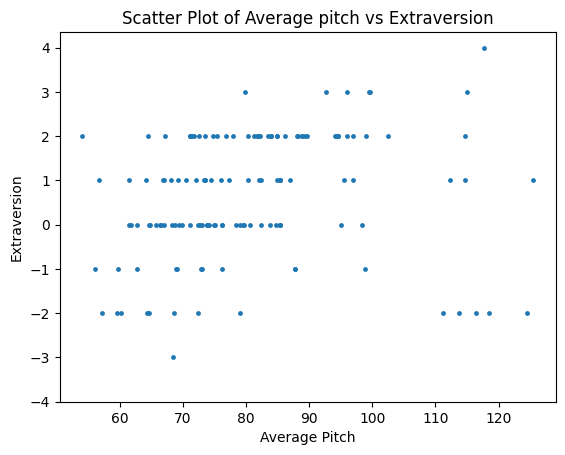

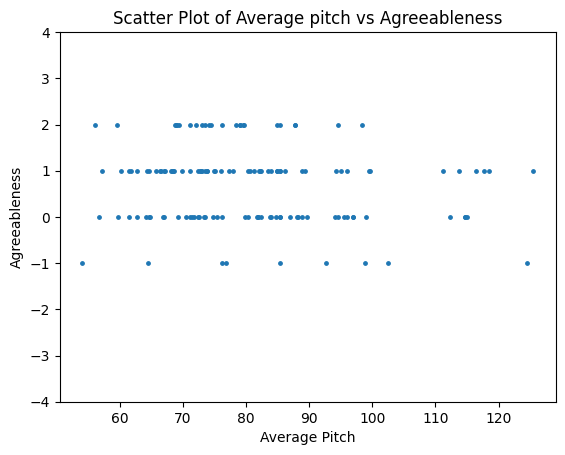

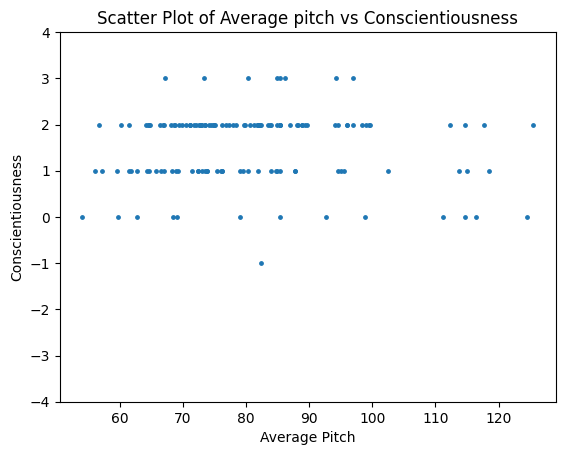

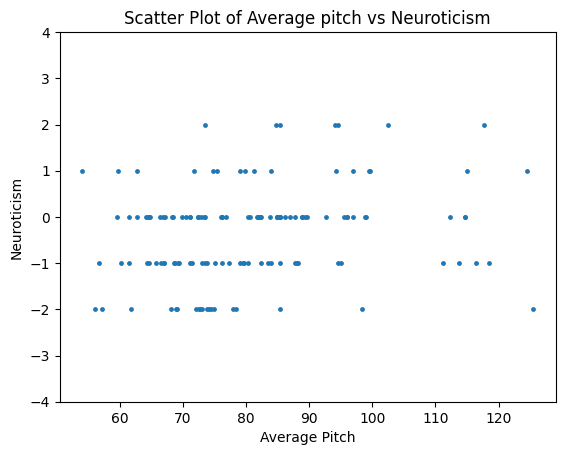

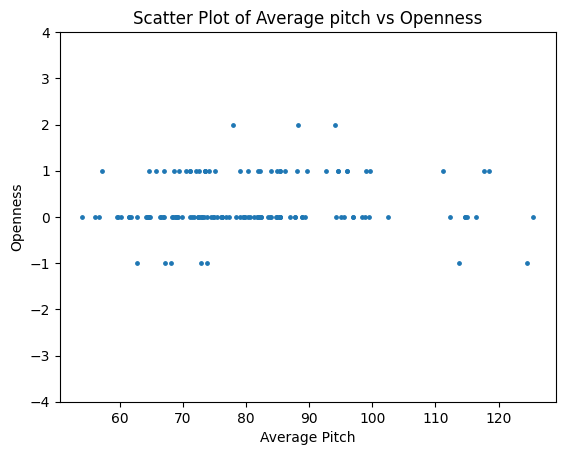

In [255]:
    
for trait in bigFive:    
    plt.scatter(femaleOnlyMax['pitchMaximum'], femaleOnlyMax[trait], s=6)
    # femaleOnlyAv.plot(x='pitchAverage', y=trait, kind='line', marker='o')

    plt.xlabel('Average Pitch')
    plt.ylabel(trait)
    plt.title(f'Scatter Plot of Average pitch vs {trait}')
    plt.yticks([-4,-3,-2,-1,0,1,2,3,4]) 
    plt.show()

# for trait in bigFive:    
#     plt.scatter(femaleOnlyAv['pitchAverage'], femaleOnlyAv[trait], s=6)
#     # femaleOnlyAv.plot(x='pitchAverage', y=trait, kind='line', marker='o')

#     plt.xlabel('Average Pitch')
#     plt.ylabel(trait)
#     plt.title(f'Scatter Plot of Average pitch vs {trait}')
#     plt.yticks([-4,-3,-2,-1,0,1,2,3,4]) 
#     # plt.show()

# for trait in bigFive:    
#     plt.scatter(maleOnlyMax['pitchMaximum'], maleOnlyMax[trait], s=6)
#     # femaleOnlyAv.plot(x='pitchAverage', y=trait, kind='line', marker='o')

#     plt.xlabel('Average Pitch')
#     plt.ylabel(trait)
#     plt.title(f'Scatter Plot of Average pitch vs {trait}')
#     plt.yticks([-4,-3,-2,-1,0,1,2,3,4]) 
#     plt.show()


In [264]:
display(Markdown('## Max Pitch'))
for trait in bigFive:
    rho, p = spearmanr(pitchWithFeaturesMax['pitchMaximum'],pitchWithFeaturesMax[trait])
    print(trait,': ','rho = ',rho, ' p =',p)

display(Markdown('## Average Pitch'))
for trait in bigFive:
    rho, p = spearmanr(pitchWithFeaturesAv['pitchAverage'],pitchWithFeaturesAv[trait])
    print(trait,': ','rho = ',rho, ' p =',p)


display(Markdown('## Female Average Pitch'))
for trait in bigFive:
    rho, p = spearmanr(femaleOnlyAv['pitchAverage'],femaleOnlyAv[trait])
    print(trait,': ','rho = ',rho, ' p =',p)

display(Markdown('## Male Average Pitch'))
for trait in bigFive:
    rho, p = spearmanr(maleOnlyAv['pitchAverage'],maleOnlyAv[trait])
    print(trait,': ','rho = ',rho, ' p =',p)
 

display(Markdown('## Female Max Pitch'))
for trait in bigFive:
    rho, p = spearmanr(femaleOnlyMax['pitchMaximum'],femaleOnlyMax[trait])
    print(trait,': ','rho = ',rho, ' p =',p)

display(Markdown('## Male Max Pitch'))
for trait in bigFive:
    rho, p = spearmanr(maleOnlyMax['pitchMaximum'],maleOnlyMax[trait])
    print(trait,': ','rho = ',rho, ' p =',p)


## Max Pitch

Extraversion :  rho =  -0.10283717490312676  p = 0.009340589052789892
Agreeableness :  rho =  0.015483050443770643  p = 0.6962869101686138
Conscientiousness :  rho =  -0.1102040522510933  p = 0.00532575475226983
Neuroticism :  rho =  -0.071551740111929  p = 0.07090702453314625
Openness :  rho =  0.002644724910581529  p = 0.9468433599267012


## Average Pitch

Extraversion :  rho =  0.049744540466341254  p = 0.20955374561462803
Agreeableness :  rho =  0.06419478257190331  p = 0.10523963290631286
Conscientiousness :  rho =  0.01823954573697319  p = 0.6456301224490026
Neuroticism :  rho =  0.017132789889760046  p = 0.6657890788510118
Openness :  rho =  -0.0026649418631448196  p = 0.9464376241884891


## Female Average Pitch

...

Extraversion :  rho =  0.038375573570103544  p = 0.39137206818043335
Agreeableness :  rho =  0.06705999442646791  p = 0.1338881112713965
Conscientiousness :  rho =  -0.049441586394169214  p = 0.2693486419873125
Neuroticism :  rho =  -0.023286812178485376  p = 0.6030650044314942
Openness :  rho =  -2.9202511758581542e-05  p = 0.9994797729516991


## Female Max Pitch

Extraversion :  rho =  0.3433738890238845  p = 3.9931647350862484e-05
Agreeableness :  rho =  -0.12728425418398964  p = 0.1382846922032886
Conscientiousness :  rho =  0.07341275913348504  p = 0.3939076339514298
Neuroticism :  rho =  0.24833182544504573  p = 0.003433563284808712
Openness :  rho =  0.14149585436987186  p = 0.09908605333682444


## Male Max Pitch

Extraversion :  rho =  -0.175082517738112  p = 8.163170517835803e-05
Agreeableness :  rho =  0.02615944001579753  p = 0.5591093673545378
Conscientiousness :  rho =  -0.15433935057520515  p = 0.0005267977365312254
Neuroticism :  rho =  -0.12837935903258316  p = 0.00399875298629654
Openness :  rho =  -0.022356362130611023  p = 0.6176275346625884


In [261]:
# SPLIT PER GENDER
import numpy as np

femaleOnlyMax = mergedDfMax[mergedDfMax['Gender'] == 'F']
maleOnlyMax = mergedDfMax[mergedDfMax['Gender'] == 'M']

print('Female min from max pitch in recording: ', femaleOnlyMax['pitchMaximum'].min(), 'Female max: ', femaleOnlyMax['pitchMaximum'].max())

print('Male min from max pitch in recording: ', maleOnlyMax['pitchMaximum'].min(), 'Male max: ', maleOnlyMax['pitchMaximum'].max())

femaleOnlyMean = mergedDf[mergedDf['Gender'] == 'F']
maleOnlyMean = mergedDf[mergedDf['Gender'] == 'M']

print('Female min from mean pitch in recording: ', femaleOnlyMean['pitchAverage'].min(), 'Female max: ', femaleOnlyMean['pitchAverage'].max())

print('Male min from mean pitch in recording: ', maleOnlyMean['pitchAverage'].min(), 'Male max: ', maleOnlyMean['pitchAverage'].max())

Female min from max pitch in recording:  54.10256 Female max:  125.4902
Male min from max pitch in recording:  34.4086 Male max:  125.4902
Female min from mean pitch in recording:  -0.16925858235582011 Female max:  0.6922535460358057
Male min from mean pitch in recording:  -3.835432096774194 Male max:  1.7524451316239318


In [220]:
# ALL possible combinations within sex for mean.
from itertools import combinations


pairsMale = list(combinations(maleOnlyMean['pitchAverage'], 2))
pairsMale_df = pd.DataFrame(pairsMale, columns=['1', '2'])
rhoM, pM = spearmanr(pairsMale_df['1'],pairsMale_df['2'])
print(rhoM,pM)

pairsFemale = list(combinations(femaleOnlyMean['pitchAverage'], 2))
pairsFemale_df = pd.DataFrame(pairsFemale, columns=['1', '2'])
rhoF, pF = spearmanr(pairsFemale_df['1'],pairsFemale_df['2'])
print(rhoF,pF)


-0.001671159076027673 0.554233003043846
-0.003708552300906954 0.7204177419461661
